In [3]:
import pandas as pd


In [1]:
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("../data/sprzedaz.csv", sep=";")
df.head()

,id,kanal,segment,wartosc
0,1,Internet,A,120
1,2,internet,B,250
2,3,Sklep,A,90
3,4,SKLEP,B,180
4,5,internet,A,310


In [5]:
print(df.shape)         # ile wierszy i kolumn
print(df.dtypes)        # jakiego rodzaju są dane
print(df.isna().sum())  # ile pustych miejsc
print(df.duplicated().sum())  # ile powtórek

(12, 4)
id         int64
kanal        str
segment      str
wartosc    int64
dtype: object
id         0
kanal      0
segment    0
wartosc    0
dtype: int64
0


In [6]:
df["wartosc"].describe()

count     12.000000
mean     187.500000
std       95.262794
min       80.000000
25%      117.500000
50%      170.000000
75%      227.500000
max      400.000000
Name: wartosc, dtype: float64

In [7]:
df["kanal"].value_counts()

kanal
internet     3
Internet     2
Sklep        2
SKLEP        2
sklep        2
internet     1
Name: count, dtype: int64

In [8]:
df["kanal"] = (
    df["kanal"]
    .str.strip()   # usuń spacje z brzegów
    .str.lower()   # zrób małe litery
)
df["kanal"].value_counts()

kanal
internet    6
sklep       6
Name: count, dtype: int64

In [9]:
# 1. ile zamówień w każdym kanale
print(df.groupby("kanal")["wartosc"].count())

# 2. suma wartości w każdym kanale
sprzedaz = df.groupby("kanal")["wartosc"].sum()
print(sprzedaz)

# 3. średnia
print("Średnia:", df["wartosc"].mean())

# 4. mediana (wartość ze środka)
print("Mediana:", df["wartosc"].median())

kanal
internet    6
sklep       6
Name: wartosc, dtype: int64
kanal
internet    1490
sklep        760
Name: wartosc, dtype: int64
Średnia: 187.5
Mediana: 170.0


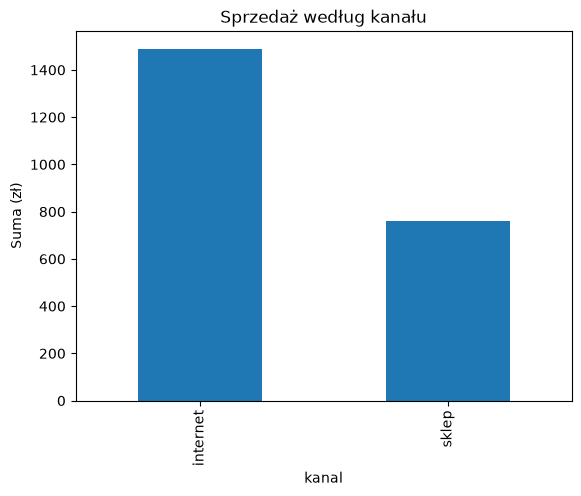

In [10]:
sprzedaz.plot(kind="bar")
plt.title("Sprzedaż według kanału")
plt.ylabel("Suma (zł)")
plt.show()